## Why NumPy isn't Slow

Now you know that Python is an interpreted language, you might wonder why e.g. NumPy and PyTorch are still reasonably fast, despite both are Python packages. Even when you're working with large images, NumPy or PyTorch functions don't feel slow at all. This is because both packages are largely written in a compiled language! All [performance-critical NumPy code](https://github.com/numpy/numpy/tree/main/numpy/_core/src/umath) is written in C, some C++, and some components make use of Fortran libraries. PyTorch's [tensor library, ATen](https://github.com/pytorch/pytorch/tree/main/aten/src/ATen), is written in C++. Therefore, our Python image analysis algorithms can still be reasonably fast, as long as we can efficiently define them *in terms of NumPy operations* (or operations available in other packages that make use of compiled code).

Take, for example, an algorithm for calculating the mean squared difference between two arrays `x` and `y`:

$\frac{1}{n}\sum_{i=0}^{n-1}(x_i-y_i)^2$

A naive but conceptually optimal implementation looks like this:

In [1]:
def msd_naive(x: np.ndarray, y:  np.ndarray) -> float:
    n = len(x)  # The number of values in the array
    sum = 0.0  # Initialize the sum to 0.

    # Iterate over all values.
    for i in range(n):
        sum += (x[i] - y[i])**2  # Calculate the squared difference.

    return sum / n  # Calculate and return the mean.

Although this implementation just iterates once over both arrays, it is slow because the Python interpreter is involved in each iteration.

In terms of NumPy operations, the algorithm can be rewritten like this:

In [2]:
import numpy as np


def msd_numpy(x: np.ndarray, y:  np.ndarray) -> float:
    return np.mean((x - y) ** 2)

In this implementation, NumPy takes care of iterating over the arrays (there is no Python `for`-loop anymore). This code executes much faster, though it is conceptually less optimal:

* Numpy first iterates over both arrays and calculates `(x - y)`. The differences are stored in a temporary array.
* It then iterates over the temporary array with differences and calculates the squared values. The squared values are stored in another temporary array.
* Finally, it iterates over the temporary array with squared values and calculates the mean.

Despite the additional iterations, it is two orders of magnitude (!) faster than the naive implementation:

In [3]:
from timeit import timeit


# Create two arrays with 100k normally distributed random numbers.
x = np.random.randn(100000)
y = np.random.randn(100000)

# Evaluate the NumPy and naive implementations 100× and measure the total duration.
duration_numpy = timeit(lambda: msd_numpy(x, y), number=100)
duration_naive = timeit(lambda: msd_naive(x, y), number=100)

print(f"The NumPy version is {duration_naive / duration_numpy:.0f}× faster.")

The NumPy version is 201× faster.


NumPy is particularly efficient for algorithms that perform lots of regular numerical operations on large arrays. But unfortunately, not all algorithms can be efficiently implemented in such a way. Take, for example, the [bilateral filter](https://en.wikipedia.org/wiki/Bilateral_filter). This is an anisotropic, edge-preserving filter that reduces noise by averaging a local neighborhood of pixels. It not only takes spatial distance into account when averaging pixel values, but it also uses the difference in pixel values. Pixels with a large difference in intensity contribute less to the average. An algorithm like this can't be efficiently implemented in terms of NumPy operations because the calculation for each pixel depends on a local neighborhood, involving many neighbor pixels.

Below is an implementation of a 1-dimensional bilateral filter:

In [4]:
import math

from matplotlib import pyplot as plt


def bilateral_filter(data: np.ndarray, sigma_s: float, sigma_r: float) -> np.ndarray:
    """
    Applies a 1-dimensional bilateral filter.

    :param data: A 1-dimensional numpy array.
    :param sigma_s: The spatial standard deviation of the spatial kernel (sample distance).
    :param sigma_r: The standard deviation of the range kernel (sample values).
    :return: A filtered 1-dimensional numpy array.
    """
    # The kernel size is at least 3× the spatial SD.
    kernel_size = math.ceil(3 * sigma_s)

    # Initialize the result as an array of zeros with the same shape and datatype as the data.
    result = np.zeros_like(data)

    # Iterate over the data and apply the filter to each sample.
    for i in range(data.shape[0]):
        weight_sum = 0.0  # We need to normalize the average to the sum of weights.

        # First and last neighbor samples to include in the kernel for sample i.
        start = max(i - kernel_size, 0)
        end = min(i + kernel_size, data.shape[0] - 1)

        # Iterate over the samples in the neighborhood.
        for j in range(start, end + 1):
            s = i - j  # Spatial distance between samples
            r = data[i] - data[j]  # Difference in sample values

            weight_s = np.exp(-s**2 / (2 * sigma_s**2))  # Spatial weight (sample distance)
            weight_r = np.exp(-r**2 / (2 * sigma_r**2))  # Range weight (sample values)
            weight = weight_s + weight_r  # Net weight is the product of the spatial and range weight.

            result[i] += weight * data[j]  # Add the contribution of sample j.
            weight_sum += weight  # Add the weight for sample j to the sum.

        # Normalize the average for pixel i.
        result[i] /= weight_sum

    return result

When this filter is applied to a noisy signal, it reduces the noise while preserving steep edges:

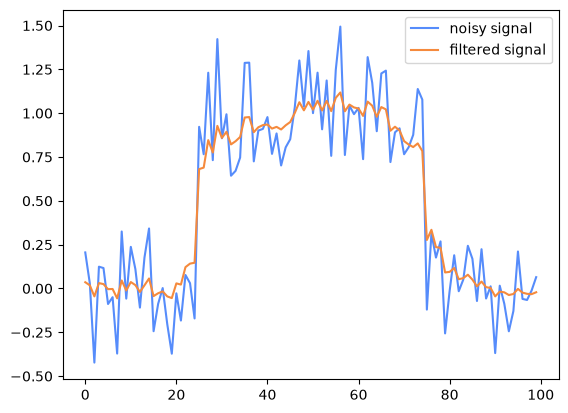

In [5]:
# Create a 1-dimensional sample signal with 100 samples and a block pulse. Add Gaussian noise.
signal = np.zeros(100)
signal[25:75] = 1
noise = 0.2 * np.random.randn(100)
data = signal + noise

# Apply the bilateral filter to the sample data. Use a spatial SD of 3 pixels and a range SD of 0.4.
result = bilateral_filter(data, 4, 0.4)

# Plot the noisy signal and the result. Note how the steep edges of the block pulse are preserved.
plt.plot(data)
plt.plot(result)
plt.legend(['noisy signal', 'filtered signal'])
plt.show()

Applying this filter to a small 1-dimensional array is not noticeably slow, but a 3D version applied to a large 3D volume could take several minutes or hours, depending on the size of the spatial kernel. It takes that long because each iteration involves overhead from the Python interpreter, requiring more steps to execute the calculations on the CPU than an equivalent function from a compiled library.

## Compiled Libraries

When an algorithm like the above becomes a *bottleneck*, i.e. when it is the time-limiting factor in your work, you could consider implementing it in a compiled language and call this compiled library function from your interpreted code.

A compiled library is also known as a *dynamically linked library* or *shared library*. In essence, this is just a file containing functions in machine code. Windows uses the extension `.dll`, macOS uses `.dylib`, and Linux uses `.so`.

The `ctypes` Python module allows us to load compiled libraries and call their functions. `ctypes` provides C-compatible data types, and allows calling functions in compiled libraries that have a C-style interface. It can be used to wrap these libraries in Python code. Although this may sound quite complicated, the C-style interface just describes the function name and the C-compatible datatypes for the function arguments and return value. Many other interpreted languages, like [MATLAB](https://nl.mathworks.com/help/matlab/ref/loadlibrary.html) and [R](https://www.rdocumentation.org/link/dyn.load), also allow loading compiled libraries with a C-style interface.

Besides a C-style interface, compiled libraries can have other language-specific interfaces. Examples are `.pyd` files (Python extension interface), and `.mexw64`/`.mexmaca64`/`.mexa64` files (MATLAB extension interface). Such libraries can be used in Python or MATLAB like any other module.

## An Example: The Bilateral Filter in C

Let's revisit the 1-dimensional bilateral filter that we just used. A nearly one-to-one translation into C would look like this:

::: {.panel-tabset}

## C

```c
#include "filters.h"

#include <stddef.h>   // Provides NULL and size_t
#include <math.h>     // Provides exp()


//  Applies a 1-dimensional bilateral filter.
//  Returns 0 on success, -1 on invalid arguments.
int bilateral_filter(
    const double *data,    // Pointer to a 1-dimensional array.
    const size_t length,   // Number of elements in 'data'.
    const double sigma_s,  // The spatial standard deviation of the spatial kernel (sample distance).
    const double sigma_r,  // The standard deviation of the range kernel (sample values).
    double *result         // Pointer to the output array (must have at least 'length' elements).
) {
    // Make sure that data and result point to valid arrays, and that the SD's are positive.
    if (data == NULL || result == NULL || sigma_s <= 0.0 || sigma_r <= 0.0) {
        return -1;
    }

    // The kernel size is at least 3× the spatial SD.
    const size_t kernel_size = (size_t)ceil(3.0 * sigma_s);

    // Iterate over the data and apply the filter to each sample.
    for (size_t i = 0; i < length; i++) {
        double weight_sum = 0.0;  // We need to normalize the average to the sum of weights.

        // First and last neighbor samples to include in the kernel for sample i.
        const size_t start = i > kernel_size ? i - kernel_size : 0;
        const size_t end = i + kernel_size < length - 1 ? i + kernel_size: length - 1;

        result[i] = 0.0;  // Initialize the result as zero.

        // Iterate over the samples in the neighborhood.
        for (size_t j = start; j <= end; j++) {
            const double s = (double)i - (double)j;  // Spatial distance between samples
            const double r = data[i] - data[j];  // Difference in sample values

            const double weight_s = exp(-(s * s) / (2.0 * sigma_s * sigma_s));  // Spatial weight (sample distance)
            const double weight_r = exp(-(r * r) / (2.0 * sigma_r * sigma_r));  // Range weight (sample values)
            const double weight = weight_s * weight_r;  // Net weight is the product of the spatial and range weight.

            result[i] += weight * data[j];  // Add the contribution of sample j.
            weight_sum += weight;  // Add the weight for sample j to the sum.
        }

        // Normalize the average for pixel i.
        result[i] /= weight_sum;
    }

    return 0;
}
```

## Python

```python


import math

import numpy as np



def bilateral_filter(
        data: np.ndarray,

        sigma_s: float,
        sigma_r: float

) -> np.ndarray:


    # Initialize the result as an array of zeros with the same shape and datatype as the data.
    result = np.zeros_like(data)

    # The kernel size is at least 3× the spatial SD.
    kernel_size = math.ceil(3 * sigma_s)

    # Iterate over the data and apply the filter to each sample.
    for i in range(data.shape[0]):
        weight_sum = 0.0  # We need to normalize the average to the sum of weights.

        # First and last neighbor samples to include in the kernel for sample i.
        start = max(i - kernel_size, 0)
        end = min(i + kernel_size, data.shape[0] - 1)



        # Iterate over the samples in the neighborhood.
        for j in range(start, end + 1):
            s = i - j  # Spatial distance between samples
            r = data[i] - data[j]  # Difference in sample values

            weight_s = np.exp(-s**2 / (2 * sigma_s**2))  # Spatial weight (sample distance)
            weight_r = np.exp(-r**2 / (2 * sigma_r**2))  # Range weight (sample values)
            weight = weight_s + weight_r  # Net weight is the product of the spatial and range weight.

            result[i] += weight * data[j]  # Add the contribution of sample j.
            weight_sum += weight  # Add the weight for sample j to the sum.


        # Normalize the average for pixel i.
        result[i] /= weight_sum


    return result

```

:::

Take your time to compare the C code to the Python code. Although the syntax is a little different, you can probably figure out what each line of C code does.

The C-style interface to this function is simply: `int bilateral_filter(double *, size_t, double, double, double *)`. This interface shows us the return type (`int`), the function name (`bilateral_filter`), and the datatypes for the five arguments `data`, `length`, `sigma_s`, `sigma_r`, and `result`:

**int bilateral_filter**: The first datatype mentioned is `int`: this is the datatype of the return value of `bilateral_filter()`. C has no built-in exception mechanism comparable to Python's, but it is common to return an integer as *status code*. The status code 0 usually means *no errors*. Anything else indicates that an error occurred.

**double \*data**: The datatype for `data` is `double *`. The type `double` is a 64-bit floating point number, and the asterisk (`*`) means that it is a *pointer*. The fact that it is a pointer means that `data` does not represent a value by itself, but that it points to the memory address where a value or an array of values is stored. In our case, `data` points to the array of floating point numbers that we are supposed to filter.

**size_t length**: The datatype for `length` is `size_t`. This is an unsigned integer type that is used for sizes that naturally correspond to C object sizes or memory operations. In our case `length` is the size of the array `data`. We need to give it as a separate argument because the compiler cannot determine the array length from the pointer alone.

**double sigma_s / double sigma_r**: The datatype for both `sigma_s` and `sigma_r` is `double`. This is a 64-bit floating point number. Nothing more, nothing less.

**double \*result**: Just like `data`, the argument `result` is a pointer (`*`) to an array of floating point numbers. The code assumes that this array has the same length as `data`.

Note that the code mentions `const` for some arguments, but the interface does not. This keyword is only used by the compiler to safeguard that these values are used as *constants*, and are thus not modified. The variable `result` is *not* `const`, which means that we *do* intend to change these values.

Also note that, whereas the Python code creates a new NumPy array for the result, the C code does not. The C code doesn't know about Python or NumPy, so it is much easier to let Python manage that part.

## Calling a Compiled Library from Python

Once you have compiled the C code to a library, such as `filters.dll` on Windows or `libfilters.dylib` on macOS, it can be loaded with either the `ctypes.CDLL` class or, more conveniently, NumPy's interface `load_library()`:

```python
lib = np.ctypeslib.load_library("filters", "/path/to/library")
```

This function returns a `ctypes.CDLL` object with a class attribute `bilateral_filter`. We now need to specify the C-style interface ourselves by declaring the argument types and return type:

```python
lib.bilateral_filter.argtypes = [
    ctypes.POINTER(ctypes.c_double),  # double *data
    ctypes.c_size_t,                  # size_t length
    ctypes.c_double,                  # double sigma_s
    ctypes.c_double,                  # double sigma_t
    ctypes.POINTER(ctypes.c_double),  # double *result
]
lib.bilateral_filter.restype = ctypes.c_int  # Return value
```

Before calling the library function, we need to make sure that the values in the NumPy arrays have the correct datatype. The C-type `double` is a 64-bit float, represented by `np.float64` in NumPy. We also have to make sure that all values are ordered correctly in memory. Do you remember that operations such as `np.flip` can return a view of an array with a different memory layout, without copying the underlying data? By calling [numpy.ascontiguousarray](https://numpy.org/doc/stable/reference/generated/numpy.ascontiguousarray.html) we make sure that all values are contiguous in memory, in the right order, and that the datatype is correct. If necessary, NumPy creates a copy to achieve this.

```python
data = np.ascontiguousarray(data, dtype=np.float64)
result = np.empty_like(data)  # Create an empty array for the result.
```

Now we have configured `lib.bilateral_filter` and prepared our data, we can call the C library function:

```python
status = lib.bilateral_filter(
    data.ctypes.data_as(ctypes.POINTER(ctypes.c_double)),
    data.size,
    sigma_s,
    sigma_r,
    result.ctypes.data_as(ctypes.POINTER(ctypes.c_double)),
)
```